# 06 - Clustering experiment: k-Means

Our implementation is in `src/kmeans.py`. Unlike the classifiers, k-Means **never sees the labels**:
it only groups vectors that are close together. Afterwards we compare the groups with the true
labels to ask: *do the features separate the classes on their own?*

How we score clusters against labels:
* **Purity**: label each cluster with its most common true class and count how many points that
  gets right. Purity goes up automatically with more clusters, so we also show the purity of
  *random* clusters of the same sizes.
* **NMI** (normalized mutual information, 0 to 1): how much the cluster tells you about the label.
* **ARI** (adjusted Rand index): agreement on which pairs of points belong together; random = 0.

We cluster all labelled training rows (nothing is predicted, so no validation split is needed).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score   # metrics only

from src.data import load_task, SEED, SENTIMENT_NAMES
from src.preprocessing import Preprocessor
from src.kmeans import KMeans
from src.utils import COLORS, save_table, save_figure, set_seed

set_seed()


def purity(y, clusters):
    return sum(np.bincount(y[clusters == c]).max() for c in np.unique(clusters)) / len(y)


def scores(y, clusters):
    shuffled = np.random.default_rng(SEED).permutation(clusters)   # same cluster sizes, random members
    return dict(purity=purity(y, clusters), purity_random=purity(y, shuffled),
                nmi=normalized_mutual_info_score(y, clusters), ari=adjusted_rand_score(y, clusters))

## 1. Sentiment: do tweets split into Negative / Neutral / Positive by themselves?

In [2]:
Xs, ys, _, _ = load_task("sentiment")
rows, sentiment_models = [], {}
for name, prep in (("standardized", Preprocessor("standardize")),
                   ("standardized + PCA-50", Preprocessor("standardize", pca_dims=50))):
    Z = prep.fit_transform(Xs)
    for k in range(2, 11):
        km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(Z)
        sentiment_models[(name, k)] = km
        rows.append(dict(representation=name, k=k, inertia=km.inertia, **scores(ys, km.labels)))
sentiment_k = pd.DataFrame(rows)
save_table(sentiment_k, "kmeans_sentiment")
sentiment_k.round(4)

,representation,k,inertia,purity,purity_random,nmi,ari
0,standardized,2,8.880832e+06,0.3914,0.3351,0.0117,0.0137
1,standardized,3,8.674731e+06,0.4231,0.3392,0.0191,0.0203
2,standardized,4,8.523294e+06,0.4258,0.3412,0.0212,0.0216
3,standardized,5,8.386093e+06,0.4208,0.3449,0.0281,0.0220
4,standardized,6,8.283277e+06,0.4202,0.3448,0.0269,0.0211
5,standardized,7,8.197572e+06,0.4234,0.3449,0.0260,0.0210
6,standardized,8,8.120103e+06,0.4436,0.3445,0.0308,0.0239
7,standardized,9,8.038489e+06,0.4451,0.3452,0.0325,0.0239
8,standardized,10,7.974597e+06,0.4562,0.3459,0.0410,0.0268
9,standardized + PCA-50,2,5.174636e+06,0.3922,0.3352,0.0120,0.0141


k = 3: how the true labels are spread over the 3 clusters
true label  Negative  Neutral  Positive
cluster                                
0                386      756       463
1               1345     1632      2052
2               2269     1612      1485 

true label  Negative  Neutral  Positive
cluster                                
0              0.240    0.471     0.288
1              0.267    0.325     0.408
2              0.423    0.300     0.277


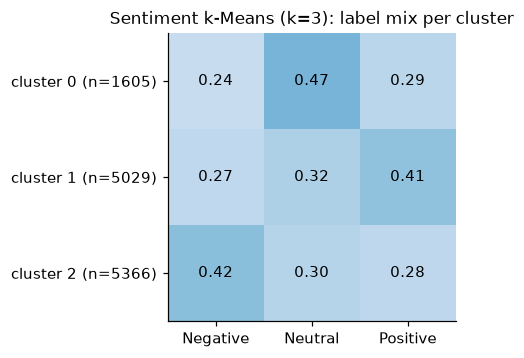

In [3]:
km3 = sentiment_models[("standardized", 3)]
table = pd.crosstab(pd.Series(km3.labels, name="cluster"),
                    pd.Series([SENTIMENT_NAMES[i] for i in ys], name="true label"))[SENTIMENT_NAMES]
share = table.div(table.sum(axis=1), axis=0)
print("k = 3: how the true labels are spread over the 3 clusters")
print(table, "\n")
print(share.round(3))

fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.imshow(share.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3))
ax.set_xticklabels(SENTIMENT_NAMES)
ax.set_yticks(range(3))
ax.set_yticklabels([f"cluster {c} (n={n})" for c, n in zip(table.index, table.sum(axis=1))])
for i in range(3):
    for j in range(3):
        v = share.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > .5 else "black")
ax.set_title("Sentiment k-Means (k=3): label mix per cluster")
ax.grid(False)
save_figure(fig, "06_kmeans_sentiment_k3")
plt.show()

**No.** With k = 3 every cluster contains lots of all three sentiments: purity is about 0.42 (random
clusters: 0.34) and NMI about 0.02 (0 = no relation). The biggest structure in these BERT
embeddings is something other than sentiment (topic, length, style...). PCA-50 first changes
nothing. This matches notebook 01: sentiment lives in a few weak directions, which supervised
models can find (about 68% accuracy) but clustering does not.

## 2. Images: do the 50 classes form 50 clusters?
We use Hellinger-transformed histograms (Euclidean k-Means on them is a good match for histograms).

In [4]:
Xi, yi, _, _ = load_task("image")
Zi = Preprocessor("hellinger").fit_transform(Xi)
rows, image_models = [], {}
for k in (10, 25, 50, 100, 200):
    km = KMeans(n_clusters=k, n_init=3, max_iter=100, random_state=SEED).fit(Zi)
    image_models[k] = km
    rows.append(dict(k=k, inertia=km.inertia, **scores(yi, km.labels)))
    print(f"k={k} done")
image_k = pd.DataFrame(rows)
save_table(image_k, "kmeans_image")
image_k.round(4)

k=10 done


k=25 done


k=50 done


k=100 done


k=200 done


,k,inertia,purity,purity_random,nmi,ari
0,10,15562.3620,0.0460,0.0274,0.0313,0.0068
1,25,15162.6690,0.0754,0.0330,0.0815,0.0163
2,50,14869.2353,0.1076,0.0368,0.1229,0.0252
3,100,14620.6059,0.1367,0.0458,0.1609,0.0293
4,200,14341.7042,0.1713,0.0570,0.2001,0.0305


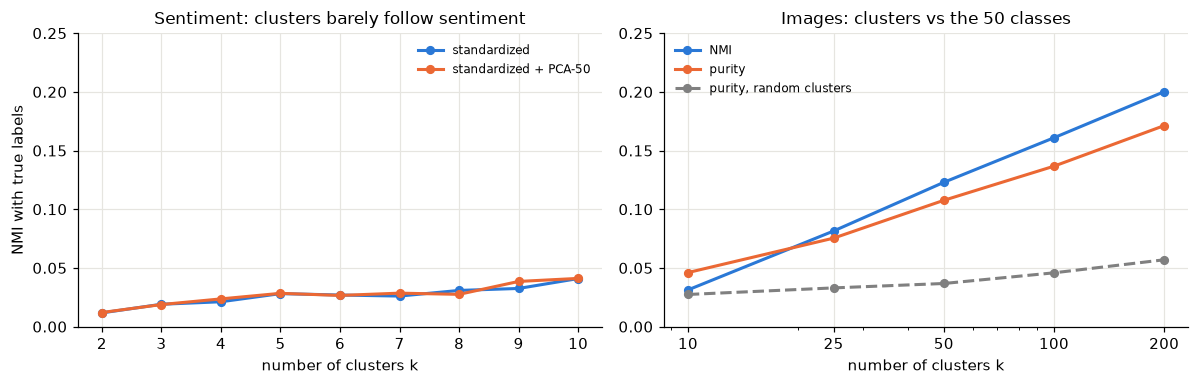

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for j, name in enumerate(("standardized", "standardized + PCA-50")):
    r = sentiment_k[sentiment_k.representation == name]
    axes[0].plot(r.k, r.nmi, marker="o", color=COLORS[j], label=name)
axes[0].set_xlabel("number of clusters k")
axes[0].set_ylabel("NMI with true labels")
axes[0].set_title("Sentiment: clusters barely follow sentiment")
axes[1].plot(image_k.k, image_k.nmi, marker="o", color=COLORS[0], label="NMI")
axes[1].plot(image_k.k, image_k.purity, marker="o", color=COLORS[1], label="purity")
axes[1].plot(image_k.k, image_k.purity_random, marker="o", color="gray", linestyle="--", label="purity, random clusters")
axes[1].set_xscale("log")
axes[1].set_xticks(image_k.k)
axes[1].set_xticklabels(image_k.k)
axes[1].set_xlabel("number of clusters k")
axes[1].set_title("Images: clusters vs the 50 classes")
for ax in axes:
    ax.set_ylim(0, 0.25)     # same scale on both panels
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "06_kmeans_k_sweep")
plt.show()

**Only weakly.** With k = 50 a cluster's majority class covers about 11% of its images (random:
about 4%). Purity and NMI keep rising up to k = 200, which fits notebook 02: each class is many small
groups of near-relatives rather than one big blob, and more, smaller clusters can follow those groups.

### Which classes end up in the same clusters?
For k = 50, the "co-clustering" score of two classes = the probability that a random image of class
A and a random image of class B fall in the same cluster. High = k-Means can't tell them apart.

In [6]:
P = pd.crosstab(yi, image_models[50].labels).to_numpy().astype(float)
P = P / P.sum(axis=1, keepdims=True)       # row a = how class a is spread over the clusters
S = P @ P.T                                # S[a, b] = P(same cluster)
upper = np.triu_indices(50, k=1)
pairs = pd.DataFrame(dict(class_a=upper[0], class_b=upper[1], same_cluster_prob=S[upper]))
pairs = pairs.sort_values("same_cluster_prob", ascending=False)
save_table(pairs, "kmeans_image_coclustered_pairs")      # notebook 07 compares these with model confusions
print("most co-clustered class pairs:")
print(pairs.head(10).round(3).to_string(index=False))

most co-clustered class pairs:
 class_a  class_b  same_cluster_prob
      45       48              0.110
       2        3              0.053
       2        4              0.053
      12       25              0.051
      37       39              0.049
      14       25              0.048
      20       23              0.048
      12       14              0.046
      21       23              0.044
       3        4              0.043
